# Lernpfad: Personenerkennung Schritt für Schritt

Dieses Notebook geht den ganzen Weg einmal langsam durch: von der Datei bis zur Entscheidung, welche Person in einem Clip geht. Es benutzt genau die Funktionen aus `laden.py`, `fenster.py`, `merkmale.py` und `modelle.py`, die auch `experimente.py` verwendet.

**So arbeitest du damit**
1. Zelle für Zelle ausführen (Shift + Enter) und die Ausgabe ansehen.
2. Nach jedem Abschnitt steht eine **Kontrollfrage**. Beantworte sie laut und in eigenen Worten, bevor du weitermachst. Genau so wird im Fachgespräch gefragt.
3. Erst danach in `docs/FACHGESPRAECH.md` nachsehen, ob die wichtigen Punkte drin waren.
4. Ändere Werte in `config.py` (z. B. `FENSTER_S` oder `GAP_S`), führe das Notebook neu aus und erkläre, was sich ändert.

Ohne echte Daten läuft alles mit künstlichen Beispieldaten aus `beispieldaten.py`. **Die Zahlen daraus sagen nichts über echte Personenerkennung.**

> **Datenschutz:** Nach einem Lauf mit echten Daten vor dem Commit alle Ausgaben löschen (*Kernel → Restart Kernel and Clear Outputs*). Sonst landen Signale echter Personen im öffentlichen Repo.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import beispieldaten
import config
from fenster import block_folds, kleinster_abstand, schneide_fenster, zufalls_folds
from laden import finde_dateien, lade_trials, lies_datei
from merkmale import berechne_merkmale
from modelle import bewerte, clip_entscheidung, erstelle_modell, zusammenfassen

ORDNER = config.DEMO_ORDNER        # für echte Daten: config.DATEN_ORDNER
if ORDNER == config.DEMO_ORDNER:
    beispieldaten.erzeuge(ORDNER, n_personen=15)

15 Personen x 4 Aktivitäten x 4 Sensoren -> data_demo


## 1. Welche Dateien gibt es? (Pipeline, Abschnitt 3)

Jede Datei ist nach der Namenskonvention des Kurs-Repos benannt. Person, Aktivität, Trial und Sensor stehen schon im Dateinamen; die Datei muss dafür nicht geöffnet werden.

In [2]:
dateien = finde_dateien(ORDNER)
print(len(dateien), "Dateien")
dateien[["person", "aktivitaet", "trial", "sensor", "kanal"]].head()

240 Dateien


,person,aktivitaet,trial,sensor,kanal
0,P01,jumping-jacks,T01,ax6-ankle-right,imu
1,P01,jumping-jacks,T01,ax6-hip,imu
2,P01,jumping-jacks,T01,ax6-wrist-left,imu
3,P01,jumping-jacks,T01,ax6-wrist-right,imu
4,P01,squats,T01,ax6-ankle-right,imu


In [3]:
# Datenabdeckung: Anzahl Sensordateien pro Person und Aktivität (4 = alle Sensoren da)
pd.crosstab(dateien.person, dateien.aktivitaet).head()

aktivitaet,jumping-jacks,squats,stairs,walking
person,,,,
P01,4,4,4,4
P02,4,4,4,4
P03,4,4,4,4
P04,4,4,4,4
P05,4,4,4,4


**Kontrollfrage 1:** Woran erkennt der Code, zu welcher Person eine Datei gehört? Was passiert mit einer Datei, deren Name nicht zur Konvention passt?

## 2. Eine einzelne Datei ansehen

In [4]:
datei = dateien[dateien.aktivitaet == config.HAUPT_AKTIVITAET].iloc[0]     # eine Gehen-Datei
werte = lies_datei(datei.pfad, datei.kanal)
print(datei.pfad)
werte.head()

data_demo/20261117_P01_HAR-walking_T01_ax6-ankle-right_imu_proc.csv


,zeit,acc_x,acc_y,acc_z,gyr_x,gyr_y,gyr_z
0,1.794907e+09,-0.0021,-0.0965,0.9290,-40.9872,-17.3401,5.5320
1,1.794907e+09,-0.0125,-0.1508,0.8885,-44.5447,-22.6650,-7.4744
2,1.794907e+09,-0.1010,-0.1606,0.5523,-38.4136,-25.0092,-7.5117
3,1.794907e+09,-0.1729,-0.2790,0.4104,-30.9068,-30.9031,-16.1076
4,1.794907e+09,-0.4358,-0.2679,0.2589,-34.3807,-41.8342,-27.8760


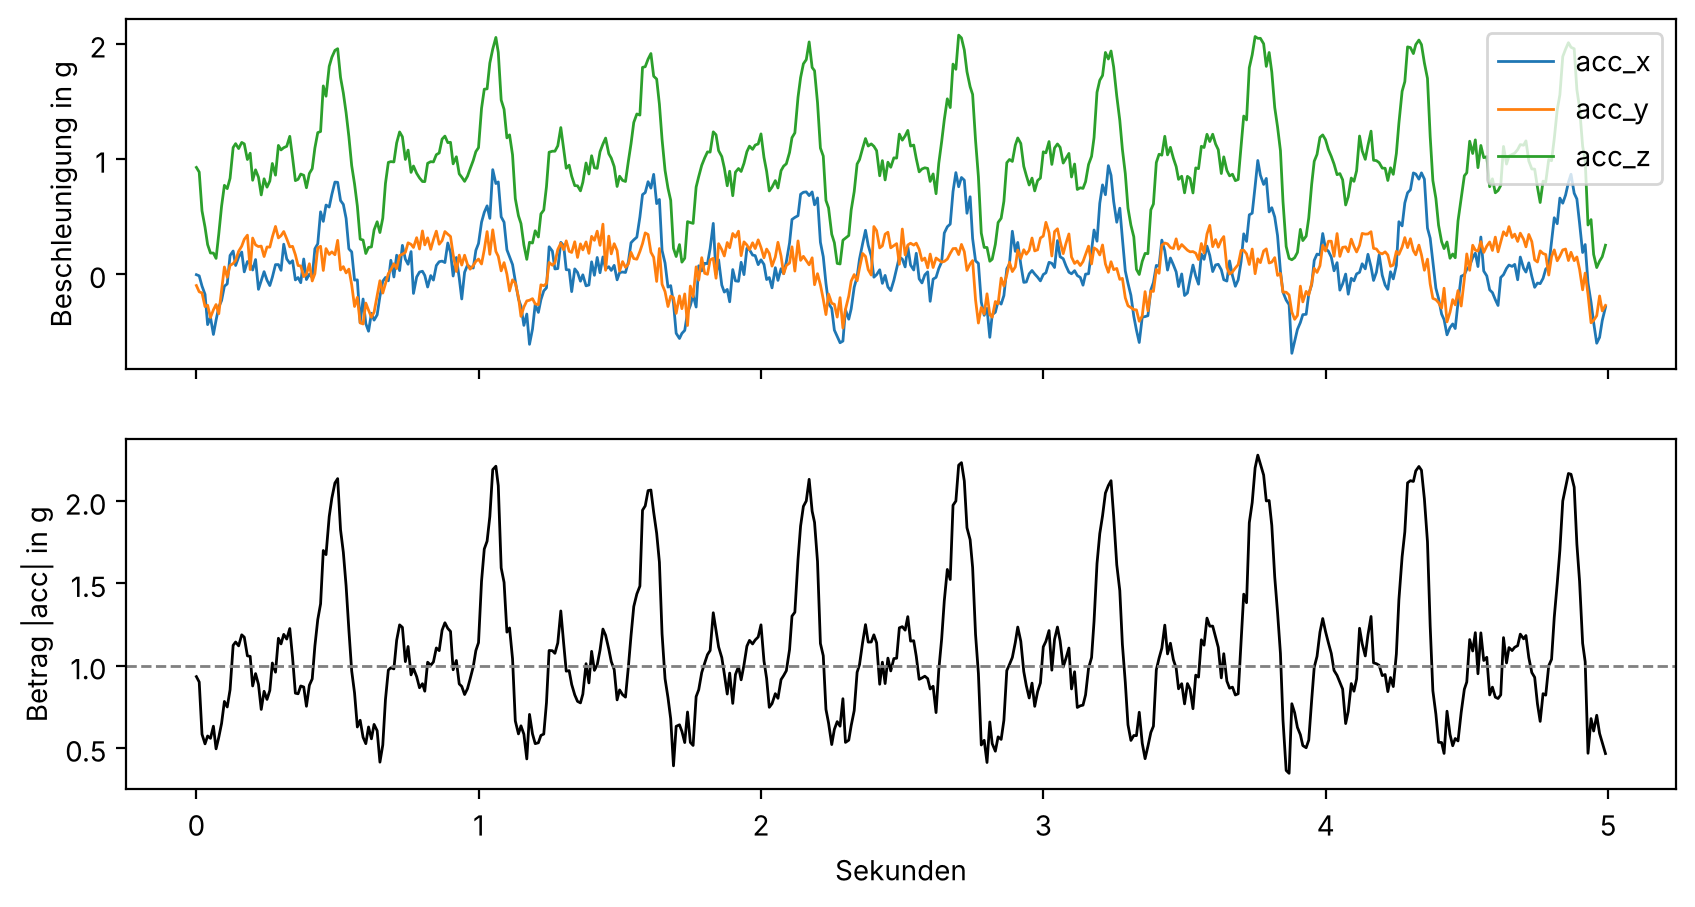

In [5]:
ausschnitt = werte[werte.zeit < werte.zeit.iloc[0] + 5]          # die ersten 5 Sekunden
t = ausschnitt.zeit - ausschnitt.zeit.iloc[0]
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
for achse in "xyz":
    ax[0].plot(t, ausschnitt[f"acc_{achse}"], label=f"acc_{achse}", lw=1)
ax[0].set_ylabel("Beschleunigung in g")
ax[0].legend(loc="upper right")
betrag = np.linalg.norm(ausschnitt[["acc_x", "acc_y", "acc_z"]], axis=1)
ax[1].plot(t, betrag, color="black", lw=1)
ax[1].axhline(1, color="gray", ls="--", lw=1)
ax[1].set_ylabel("Betrag |acc| in g")
ax[1].set_xlabel("Sekunden")
plt.show()

Oben schwanken die drei Achsen um verschiedene Mittelwerte. Das ist die Schwerkraft: Je nachdem, wie der Sensor gedreht am Körper sitzt, verteilt sie sich anders auf x, y und z. Unten der Betrag $|a| = \sqrt{a_x^2 + a_y^2 + a_z^2}$. Er schwankt um 1 g, egal wie der Sensor gedreht ist.

**Kontrollfrage 2:** Warum liegt der Betrag im Mittel bei etwa 1 g? Was ändert sich an den drei Achsen und was am Betrag, wenn man den Sensor um 90° gedreht anlegt?

## 3. Laden, prüfen und synchronisieren (Pipeline, Abschnitte 3 und 4)

`lade_trials` liest alle Dateien, schreibt für jede Datei eine Zeile in den Qualitätsbericht und bringt die vier Sensoren eines Trials auf ein gemeinsames 50-Hz-Raster.

In [6]:
trials, bericht = lade_trials(ORDNER)
bericht.round(2).head()

60 Trials gefunden, verwendete Sensoren: ['ax6-ankle-right', 'ax6-hip', 'ax6-wrist-left', 'ax6-wrist-right']


  Hinweis: 20261117_P03_HAR-squats_T01_ax6-wrist-left_imu_proc.csv ist in m/s² und wird in g umgerechnet


,datei,dauer_s,fs_hz,luecken,groesste_luecke_s,acc_betrag_median_g,gyr_p99_grad_s
0,20261117_P01_HAR-jumping-jacks_T01_ax6-ankle-r...,40.08,100.0,0,0.01,1.12,109.30
1,20261117_P01_HAR-jumping-jacks_T01_ax6-hip_imu...,40.39,100.0,0,0.01,0.93,113.60
2,20261117_P01_HAR-jumping-jacks_T01_ax6-wrist-l...,40.38,100.0,0,0.01,0.95,118.91
3,20261117_P01_HAR-jumping-jacks_T01_ax6-wrist-r...,40.35,100.0,0,0.01,1.16,104.67
4,20261117_P01_HAR-squats_T01_ax6-ankle-right_im...,40.37,100.0,0,0.01,1.00,57.44


In den Beispieldaten sind zwei Probleme versteckt: eine Datenlücke und eine Datei in m/s² statt in g. Die zweite hat `lies_datei` beim Laden gemeldet und umgerechnet (Ausgabe oben). Die Lücke steht im Bericht:

In [7]:
bericht[bericht.luecken > 0].round(2)

,datei,dauer_s,fs_hz,luecken,groesste_luecke_s,acc_betrag_median_g,gyr_p99_grad_s
28,20261117_P02_HAR-walking_T01_ax6-ankle-right_i...,60.27,100.0,1,1.02,1.02,71.34


In [8]:
trial = [t for t in trials if t["aktivitaet"] == config.HAUPT_AKTIVITAET][0]   # ein Gehen-Trial
print(trial["id"], "->", trial["daten"].shape, "(Zeilen = Zeitpunkte, Spalten = Kanäle)")
trial["daten"].iloc[:3, :6].round(3)

20261117_P01_HAR-walking_T01 -> (2906, 24) (Zeilen = Zeitpunkte, Spalten = Kanäle)


,ax6-ankle-right_acc_x,ax6-ankle-right_acc_y,ax6-ankle-right_acc_z,ax6-ankle-right_gyr_x,ax6-ankle-right_gyr_y,ax6-ankle-right_gyr_z
0,0.140,0.109,1.095,0.459,7.911,2.632
1,0.155,0.215,1.159,5.054,19.857,7.274
2,0.157,0.256,1.064,9.855,27.189,3.351


Nach dem Synchronisieren ist jeder Trial eine Tabelle: eine Zeile pro 1/50 Sekunde, eine Spalte pro Kanal. Vier Sensoren mal sechs Kanäle (acc und gyr, je x, y, z) ergeben 24 Spalten.

**Kontrollfrage 3:** Die Sensoren messen mit 100 Hz, wir rechnen mit 50 Hz. Warum filtern wir vorher mit einem Tiefpass bei 20 Hz? Und warum wird eine Lücke nicht einfach interpoliert?

## 4. Clips und Fenster (Pipeline, Abschnitt 8)

In [9]:
X, info = schneide_fenster(trials)
kanaele = list(trials[0]["daten"].columns)
print("X hat die Form", X.shape, "= (Fenster, Samples pro Fenster, Kanäle)")
info.head(7)

X hat die Form (1347, 150, 24) = (Fenster, Samples pro Fenster, Kanäle)


,person,aktivitaet,trial,clip_nr,clip_id,start_s,ende_s,clip_laenge_s
0,P01,jumping-jacks,20261117_P01_HAR-jumping-jacks_T01,0,20261117_P01_HAR-jumping-jacks_T01#0,0.00,3.00,7.58
1,P01,jumping-jacks,20261117_P01_HAR-jumping-jacks_T01,0,20261117_P01_HAR-jumping-jacks_T01#0,1.50,4.50,7.58
2,P01,jumping-jacks,20261117_P01_HAR-jumping-jacks_T01,0,20261117_P01_HAR-jumping-jacks_T01#0,3.00,6.00,7.58
3,P01,jumping-jacks,20261117_P01_HAR-jumping-jacks_T01,0,20261117_P01_HAR-jumping-jacks_T01#0,4.50,7.50,7.58
4,P01,jumping-jacks,20261117_P01_HAR-jumping-jacks_T01,1,20261117_P01_HAR-jumping-jacks_T01#1,7.58,10.58,7.58
5,P01,jumping-jacks,20261117_P01_HAR-jumping-jacks_T01,1,20261117_P01_HAR-jumping-jacks_T01#1,9.08,12.08,7.58
6,P01,jumping-jacks,20261117_P01_HAR-jumping-jacks_T01,1,20261117_P01_HAR-jumping-jacks_T01#1,10.58,13.58,7.58


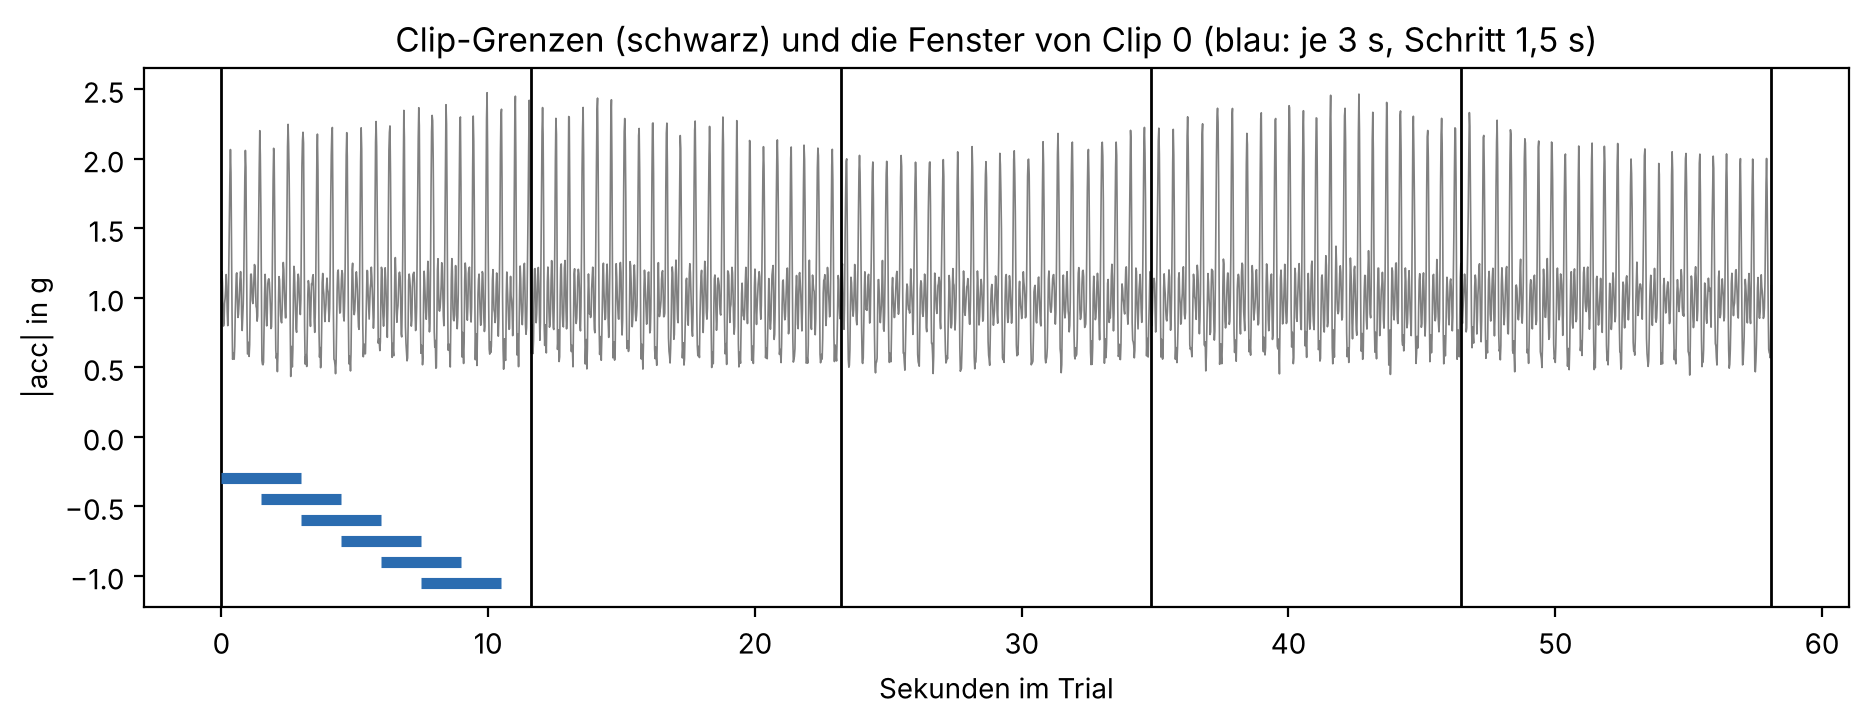

In [10]:
eins = info[info.trial == trial["id"]]
signal = np.linalg.norm(trial["daten"][kanaele[:3]], axis=1)       # Betrag des ersten Sensors
zeit = np.arange(len(signal)) / config.FS
clip_s = eins.clip_laenge_s.iloc[0]

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(zeit, signal, color="gray", lw=0.6)
for k in range(config.N_CLIPS + 1):
    ax.axvline(k * clip_s, color="black", lw=1)
for i, (_, fenster) in enumerate(eins[eins.clip_nr == 0].iterrows()):
    ax.hlines(-0.3 - 0.15 * i, fenster.start_s, fenster.ende_s, color="#2b6cb0", lw=4)
ax.set(xlabel="Sekunden im Trial", ylabel="|acc| in g",
       title="Clip-Grenzen (schwarz) und die Fenster von Clip 0 (blau: je 3 s, Schritt 1,5 s)")
plt.show()

Jeder Trial wird zuerst in fünf gleich lange Clips geteilt, erst danach wird jeder Clip in Fenster geschnitten. Deshalb reicht kein Fenster über eine Clip-Grenze. Benachbarte Fenster überlappen sich zur Hälfte.

**Kontrollfrage 4:** Wie viele Fenster passen in einen Clip dieses Trials? Rechne es mit Cliplänge, Fensterlänge und Schrittweite nach und vergleiche mit dem Bild. Warum ist Überlappung erlaubt, solange sie nur innerhalb des Trainings oder nur innerhalb des Tests vorkommt?

## 5. Der Block-Split mit Gap (Pipeline, Abschnitt 7): das Herzstück

In jedem Fold ist ein Clip pro Trial der Test-Clip, die übrigen sind Training. Trainingsfenster, die näher als 3 Sekunden am Test-Clip liegen, werden weggelassen (Gap). Fünf Clips ergeben fünf Folds; jeder Clip ist genau einmal Test.

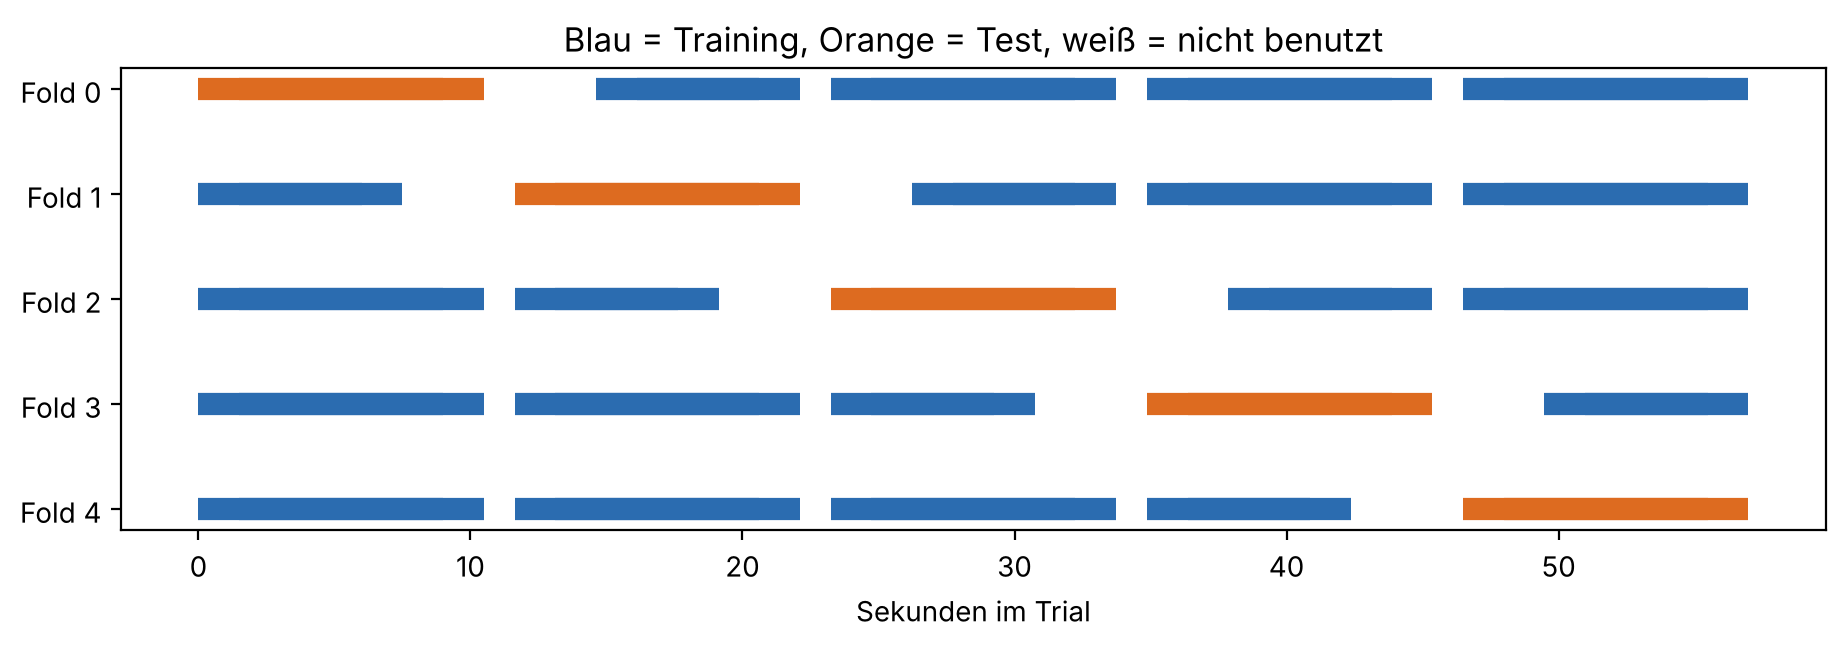

In [11]:
folds = block_folds(info)
farben = {"Training": "#2b6cb0", "Test": "#dd6b20"}
fig, ax = plt.subplots(figsize=(11, 3))
for f, (train, test) in enumerate(folds):
    for rolle, zeilen in [("Training", train), ("Test", test)]:
        auswahl = info.iloc[zeilen]
        auswahl = auswahl[auswahl.trial == trial["id"]]
        ax.hlines([f] * len(auswahl), auswahl.start_s, auswahl.ende_s, color=farben[rolle], lw=8)
ax.set(yticks=range(len(folds)), yticklabels=[f"Fold {f}" for f in range(len(folds))],
       xlabel="Sekunden im Trial", title="Blau = Training, Orange = Test, weiß = nicht benutzt")
ax.invert_yaxis()
plt.show()

In [12]:
for f, (train, test) in enumerate(folds):
    print(f"Fold {f}: {len(train):4d} Trainingsfenster, {len(test):3d} Testfenster, "
          f"kleinster Abstand Training-Test: {kleinster_abstand(info, train, test):.1f} s")

Fold 0:  956 Trainingsfenster, 270 Testfenster, kleinster Abstand Training-Test: 3.0 s
Fold 1:  839 Trainingsfenster, 267 Testfenster, kleinster Abstand Training-Test: 3.0 s
Fold 2:  827 Trainingsfenster, 270 Testfenster, kleinster Abstand Training-Test: 3.0 s
Fold 3:  836 Trainingsfenster, 270 Testfenster, kleinster Abstand Training-Test: 3.0 s
Fold 4:  957 Trainingsfenster, 270 Testfenster, kleinster Abstand Training-Test: 3.0 s


Die breiten weißen Lücken neben dem Test-Clip sind der Gap. Die schmalen weißen Streifen zwischen den anderen Clips sind Clip-Reste: Am Ende jedes Clips bleibt ein Stück übrig, in das kein ganzes Fenster mehr passt.

Der kleinste Abstand ist in jedem Fold mindestens 3 Sekunden. Dieselbe Prüfung läuft bei jedem Push als automatischer Test (`tests/test_pipeline.py`).

**Kontrollfrage 5:** Was ist Data Leakage, und wie entsteht es bei überlappenden Fenstern? Wozu braucht man zusätzlich zum Block-Split noch den Gap, und warum mindestens eine Fensterlänge?

## 6. Merkmale (Pipeline, Abschnitt 5)

In [13]:
merkmale = berechne_merkmale(X, kanaele, "alle")
print(merkmale.shape, "= (Fenster, Merkmale)")
merkmale.iloc[:3, :7].round(3)

(1347, 192) = (Fenster, Merkmale)


,ax6-ankle-right_acc_x_mean,ax6-ankle-right_acc_x_std,ax6-ankle-right_acc_x_min,ax6-ankle-right_acc_x_max,ax6-ankle-right_acc_x_rms,ax6-ankle-right_acc_x_energie,ax6-ankle-right_acc_y_mean
0,-0.083,0.470,-1.013,0.922,0.477,0.228,-0.540
1,-0.090,0.455,-0.990,0.922,0.464,0.215,-0.541
2,-0.095,0.415,-0.971,0.811,0.426,0.182,-0.509


Für jeden der 24 Kanäle gibt es sechs Kennzahlen (mean, std, min, max, rms, energie), das sind 144 Merkmale. Dazu kommen dieselben sechs Kennzahlen für den Betrag von acc und gyr jedes Sensors: 8 × 6 = 48. Zusammen 192 Merkmale pro Fenster.

**Kontrollfrage 6:** Was beschreibt der Mittelwert von `acc_z` in einem Fenster: die Bewegung der Person oder etwas anderes? Warum hängen RMS und Energie so eng zusammen?

## 7. Ein Modell trainieren und einen Clip entscheiden

Ab hier nur noch Gehen, wie in unserer Forschungsfrage.

In [14]:
gehen = (info.aktivitaet == config.HAUPT_AKTIVITAET).to_numpy()
info_g = info[gehen].reset_index(drop=True)
merkmale_g = merkmale[gehen].reset_index(drop=True)
folds_g = block_folds(info_g)

train, test = folds_g[0]
modell = erstelle_modell("Random Forest")
modell.fit(merkmale_g.iloc[train], info_g.person.iloc[train])
p = modell.predict_proba(merkmale_g.iloc[test])
print("Wahrscheinlichkeiten:", p.shape, "= (Testfenster, Personen)")

Wahrscheinlichkeiten: (90, 15) = (Testfenster, Personen)


In [15]:
# Alle Fenster eines Test-Clips, Wahrscheinlichkeiten der fünf wahrscheinlichsten Personen
clip = info_g.clip_id.iloc[test[0]]
zeilen = (info_g.clip_id.iloc[test] == clip).to_numpy()
tabelle = pd.DataFrame(p[zeilen], columns=modell.classes_)
top5 = tabelle.mean().sort_values(ascending=False).index[:5]
print("Clip:", clip, "   wahre Person:", info_g.person.iloc[test[0]])
tabelle[top5].round(2)

Clip: 20261117_P01_HAR-walking_T01#0    wahre Person: P01


,P01,P10,P03,P11,P05
0,0.93,0.02,0.01,0.00,0.02
1,0.96,0.01,0.01,0.00,0.01
2,0.94,0.04,0.00,0.01,0.00
3,0.92,0.04,0.01,0.01,0.01
4,0.89,0.04,0.01,0.02,0.01
5,0.86,0.03,0.05,0.03,0.01


In [16]:
entscheidung = clip_entscheidung(p, info_g.clip_id.iloc[test], modell.classes_)
entscheidung.head()

20261117_P01_HAR-walking_T01#0    P01
20261117_P02_HAR-walking_T01#0    P02
20261117_P03_HAR-walking_T01#0    P03
20261117_P04_HAR-walking_T01#0    P04
20261117_P05_HAR-walking_T01#0    P05
dtype: str

Jede Zeile der Tabelle ist ein Fenster, jede Spalte eine Person. Für die Clip-Entscheidung werden die Spalten gemittelt; die Person mit dem höchsten Mittelwert gewinnt. Einzelne unsichere Fenster fallen dadurch weniger ins Gewicht.

`bewerte` macht dasselbe für alle fünf Folds, in jedem Fold mit einem neuen Modell, das nur die Trainingsfenster sieht:

In [17]:
ergebnis, vorhersagen = bewerte("Random Forest", merkmale_g, info_g, folds_g)
print(ergebnis.round(3))
print()
print(zusammenfassen(ergebnis).round(3))

   fold  f1_fenster  f1_clip  acc_clip
0     0       1.000    1.000     1.000
1     1       1.000    1.000     1.000
2     2       0.822    0.822     0.867
3     3       1.000    1.000     1.000
4     4       1.000    1.000     1.000

f1_fenster_mittel    0.964
f1_clip_mittel       0.964
acc_clip_mittel      0.973
f1_fenster_sd        0.080
f1_clip_sd           0.080
acc_clip_sd          0.060
dtype: float64


Berichtet wird Mittelwert ± Standardabweichung über die Folds.

**Kontrollfrage 7:** Warum ist die Clip-Ebene meist besser als die Fenster-Ebene? Was misst Macro-F1, und warum reicht Accuracy nicht? Wo liegt das Zufallsniveau bei 15 Personen?

## 8. Warum der Split so wichtig ist

Dasselbe Modell, einmal mit dem verbotenen Zufalls-Split und einmal mit unserem Block-Split:

In [18]:
for name, folds in [("Zufällige Fenster (falsch)", zufalls_folds(info_g)), ("Block mit Gap", folds_g)]:
    ergebnis, _ = bewerte("Random Forest", merkmale_g, info_g, folds)
    abstand = min(kleinster_abstand(info_g, train, test) for train, test in folds)
    print(f"{name:28s} Macro-F1 Fenster {ergebnis.f1_fenster.mean():.3f}   "
          f"kleinster Abstand {abstand:5.1f} s")

Zufällige Fenster (falsch)   Macro-F1 Fenster 1.000   kleinster Abstand  -1.5 s


Block mit Gap                Macro-F1 Fenster 0.964   kleinster Abstand   4.0 s


Beim Zufalls-Split ist der kleinste Abstand negativ: Trainings- und Testfenster überlappen, das Modell hat Teile der Testdaten schon gesehen. Das Ergebnis wird besser, ist aber nicht ehrlich.

**Kontrollfrage 8:** Warum wird das Ergebnis beim Zufalls-Split besser, obwohl sich am Modell nichts ändert? Welche der beiden Zahlen würdet ihr auf dem Poster berichten?

## 9. Der Lage-Test: Person oder Sensorsitz? (Pipeline, Abschnitt 7, Session-Risiko)

Dasselbe Modell mit drei Merkmalssätzen:
- **alle**: wie bisher
- **nur_mittelwerte**: nur der Mittelwert jeder Achse. Er hängt vor allem davon ab, wie der Sensor gedreht sitzt (Richtung der Schwerkraft), kaum von der Bewegung.
- **nur_betraege**: nur Kennzahlen des Betrags. Sie hängen nicht davon ab, wie der Sensor gedreht sitzt.

In [19]:
for satz in ["alle", "nur_mittelwerte", "nur_betraege"]:
    m = berechne_merkmale(X[gehen], kanaele, satz)
    ergebnis, _ = bewerte("Random Forest", m, info_g, folds_g)
    print(f"{satz:16s} {m.shape[1]:4d} Merkmale   Macro-F1 Clip {ergebnis.f1_clip.mean():.3f}")

alle              192 Merkmale   Macro-F1 Clip 0.964


nur_mittelwerte    24 Merkmale   Macro-F1 Clip 1.000


nur_betraege       48 Merkmale   Macro-F1 Clip 0.802


Ist „nur_mittelwerte" fast so gut wie „alle", kann das Modell die Personen allein am Sensorsitz unterscheiden. Mit nur einer Aufnahme pro Person lässt sich dann nicht sagen, ob es den Gang oder die Befestigung gelernt hat. Genau dieses Session-Risiko sollen wir laut Pipeline ausdrücklich benennen. In `experimente.py` (E3) läuft derselbe Test zusätzlich mit dem Cross-Activity-Split.

**Kontrollfrage 9:** Wenn „nur_mittelwerte" sehr gut ist: Was hat das Modell dann gelernt? Würde es dieselbe Person an einem anderen Tag wiedererkennen? Welche Messung bräuchte man, um das zu prüfen?

## Checkliste: Das musst du ohne Notizen erklären können

- [ ] Wie aus einem Dateinamen Person, Aktivität und Sensor werden
- [ ] Warum wir synchronisieren, warum vor dem Heruntertakten ein Tiefpass kommt und was mit Lücken passiert
- [ ] Wie Clips und Fenster entstehen und wie viele Fenster in einen Clip passen
- [ ] Was Data Leakage ist und wie Block-Split plus Gap es verhindern
- [ ] Wie `kleinster_abstand` prüft, dass kein Leakage passiert
- [ ] Welche Merkmale wir berechnen und was der Mittelwert einer Achse eigentlich misst
- [ ] Warum KNN und SVM skalierte Merkmale brauchen und warum der Scaler in der Pipeline steckt
- [ ] Wie aus vielen Fensterentscheidungen eine Clip-Entscheidung wird
- [ ] Warum Macro-F1 und was Mittelwert ± Standardabweichung über die Folds bedeutet
- [ ] Was der Lage-Test zeigt und warum 100 % noch keine echte Personenerkennung beweisen